# TQH-04 — Khám phá thống kê sâu trên ba dataset ETT
**T0304 · ETT_GRID_VIS_2026 v2.0 · seed 2026 · CPU-only**

Run-all từ ROOT hoặc thư mục notebooks bằng kernel `.venv`.
Chỉ đọc sáu artifacts đã kiểm toán T0205; không sửa raw, không chạy lại engine.
Mỗi dataset được phân tích riêng theo cadence 1h/15m, không gộp số mẫu thành
thời lượng hoặc coi trạm có nhiều mẫu hơn là nóng hơn.

85/95°C là **quy ước phân tích dự án**, không phải chuẩn kỹ thuật phổ quát.
Dry (tháng 11–4)/Wet (5–10) là nhóm tháng, không tự gọi là mùa hè/đông địa phương.
Quan sát và giả thuyết được tách biệt; không dùng tương quan để khẳng định nguyên nhân.

In [1]:
from pathlib import Path
import hashlib
import json
import random
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "AGENTS.md").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.constants import (
    SEED, CADENCE_MINUTES, EXPECTED_DATASET_ROWS, MEASUREMENTS,
    LOAD_BRANCHES, DRY_MONTHS, DAY_NAMES, WARNING_TEMP_THRESHOLD,
    CRITICAL_TEMP_THRESHOLD,
)
assert SEED == 2026
random.seed(SEED)
np.random.seed(SEED)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 95, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False,
                     "font.size": 10})
NAVY, TEAL, SLATE = "#1E3A8A", "#0D9488", "#64748B"
AMBER, CRIMSON, GRID = "#D97706", "#DC2626", "#E2E8F0"
audit = json.loads((ROOT / "audit/t0205_artifacts_sync_audit.json").read_text(encoding="utf-8"))
assert audit["status"] == "PASS"
names = ["clean_ett.parquet", "load_profiles_stl.parquet", "quantile_bands.parquet",
         "lag_correlation_matrix.json", "thermal_breach_events.parquet", "loess_curves.parquet"]
source_hashes = {}
for name in names:
    path = ROOT / ("data/processed" if name == "clean_ett.parquet" else "output/artifacts") / name
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == audit["artifacts"][name]["sha256_bytes"], f"Stale audit: {name}"
    source_hashes[name] = digest
clean = pd.read_parquet(ROOT / "data/processed/clean_ett.parquet")
profiles = pd.read_parquet(ROOT / "output/artifacts/load_profiles_stl.parquet")
bands = pd.read_parquet(ROOT / "output/artifacts/quantile_bands.parquet")
lag = json.loads((ROOT / "output/artifacts/lag_correlation_matrix.json").read_text(encoding="utf-8"))
events = pd.read_parquet(ROOT / "output/artifacts/thermal_breach_events.parquet")
curves = pd.read_parquet(ROOT / "output/artifacts/loess_curves.parquet")
assert clean.groupby("dataset").size().to_dict() == EXPECTED_DATASET_ROWS
assert not clean.duplicated(["dataset", "timestamp"]).any()
data = clean.copy()
data["hour"] = data.timestamp.dt.hour
data["weekday"] = data.timestamp.dt.dayofweek
data["month"] = data.timestamp.dt.month
data["season"] = np.where(data.month.isin(DRY_MONTHS), "Dry", "Wet")
datasets = sorted(CADENCE_MINUTES)
gap_counts = {}
for dataset, group in data.groupby("dataset"):
    delta = group.timestamp.diff().dropna()
    cadence = pd.Timedelta(minutes=CADENCE_MINUTES[dataset])
    assert (delta >= cadence).all() and (delta % cadence == pd.Timedelta(0)).all()
    gap_counts[dataset] = int(delta.gt(cadence).sum())
assert gap_counts == audit["quality_audit"]["gap_counts"]
display(pd.DataFrame({"samples": clean.groupby("dataset").size(),
                      "cadence_minutes": pd.Series(CADENCE_MINUTES),
                      "observed_gaps": pd.Series(gap_counts)}))
print("Interpreter:", sys.executable)
print("Seed:", SEED, "| timezone: unknown | read-only audited inputs: six")

,samples,cadence_minutes,observed_gaps
ETTh1,17420,60,0
ETTh2,17420,60,0
ETTm1,69680,15,0


Interpreter: f:\Study Materials\specialized_subject\Visualization\Visualization_gr\data_visualization_project\.venv\Scripts\python.exe
Seed: 2026 | timezone: unknown | read-only audited inputs: six


## 1. Thống kê mô tả: OT và sáu nhánh tải
Min/max/mean/median/IQR theo dataset. Skew dùng Pandas sample skew;
kurtosis là **excess kurtosis** (chuẩn tham chiếu 0), không phải Pearson kurtosis.
Số mẫu hợp lệ đi kèm; OT dùng °C, tải giữ đơn vị nguồn chưa hiệu chuẩn.

In [2]:
rows = []
for dataset, group in data.groupby("dataset"):
    for variable in MEASUREMENTS:
        values = group[variable].dropna().astype("float64")
        q25, q75 = values.quantile([0.25, 0.75])
        rows.append({"dataset": dataset, "variable": variable, "n": len(values),
                     "min": values.min(), "max": values.max(), "mean": values.mean(),
                     "median": values.median(), "q25": q25, "q75": q75,
                     "iqr": q75 - q25, "skewness": values.skew(),
                     "excess_kurtosis": values.kurt()})
descriptive = pd.DataFrame(rows).set_index(["dataset", "variable"])
assert len(descriptive) == 21
display(descriptive.round(3))

n     min      max    mean  median     q25     q75  \
dataset variable                                                           
ETTh1   OT        17420  -4.080   46.007  13.325  11.396   6.964  18.079   
        HUFL      17420 -22.706   23.644   7.375   8.774   5.827  11.788   
        HULL      17420  -4.756   10.114   2.242   2.210   0.737   3.684   
        MUFL      17420 -25.088   17.341   4.300   5.970   3.296   8.635   
        MULL      17420  -5.934    7.747   0.882   0.959  -0.284   2.203   
        LUFL      17420  -1.188    8.498   3.066   2.833   2.315   3.625   
        LULL      17420  -1.371    3.046   0.857   0.975   0.670   1.218   
ETTh2   OT        17420  -2.647   58.877  26.609  26.577  16.469  35.586   
        HUFL      17420   0.000  107.893  37.193  37.193  30.156  44.062   
        HULL      17420 -18.680   36.439   8.538   9.131   4.523  13.152   
        MUFL      17420  11.205   93.230  43.830  41.388  37.394  46.079   
        MULL      17420  -6.594   28.736   8.323   9.302   5.683  11.258   
        LUFL      17420 -14.350   17.218  -3.424  -3.774  -9.254   2.527   
        LULL      17420 -31.462    2.932  -2.086  -1.226  -2.505   0.000   
ETTm1   OT        69680  -4.221   46.007  13.321  11.396   6.964  18.079   
        HUFL      69680 -23.242   24.180   7.414   8.841   5.827  11.788   
        HULL      69680  -5.693   10.315   2.261   2.210   0.804   3.684   
        MUFL      69680 -26.367   18.087   4.322   6.005   3.305   8.635   
        MULL      69680  -6.041    7.853   0.897   0.959  -0.284   2.203   
        LUFL      69680  -1.188    8.498   3.083   2.833   2.315   3.655   
        LULL      69680  -1.371    3.046   0.858   0.975   0.670   1.218   

                     iqr  skewness  excess_kurtosis  
dataset variable                                     
ETTh1   OT        11.115     0.968            0.778  
        HUFL       5.961    -1.378            1.952  
        HULL       2.947     0.101           -0.306  
        MUFL       5.339    -1.605            2.354  
        MULL       2.487    -0.138           -0.240  
        LUFL       1.310     1.267            2.962  
        LULL       0.548    -1.362            2.078  
ETTh2   OT        19.116     0.099           -0.811  
        HUFL      13.906     0.451            3.494  
        HULL       8.629    -0.172           -0.484  
        MUFL       8.685     2.168            5.498  
        MULL       5.575    -0.503            0.274  
        LUFL      11.781     0.076           -1.488  
        LULL       2.505    -4.029           15.656  
ETTm1   OT        11.115     0.967            0.771  
        HUFL       5.961    -1.373            1.936  
        HULL       2.880     0.106           -0.308  
        MUFL       5.330    -1.604            2.353  
        MULL       2.487    -0.131           -0.246  
        LUFL       1.340     1.243            2.780  
        LULL       0.548    -1.356            2.057

## 2. Phân phối OT và xu hướng thời gian
Histogram density theo từng dataset (không coi là kiểm định chuẩn).
Trend dùng **mean/max ngày** từ quan sát thực, không phải đường dự báo;
max ngày giữ thông tin đỉnh nhưng không thay chuỗi gốc khi xác định sự kiện.

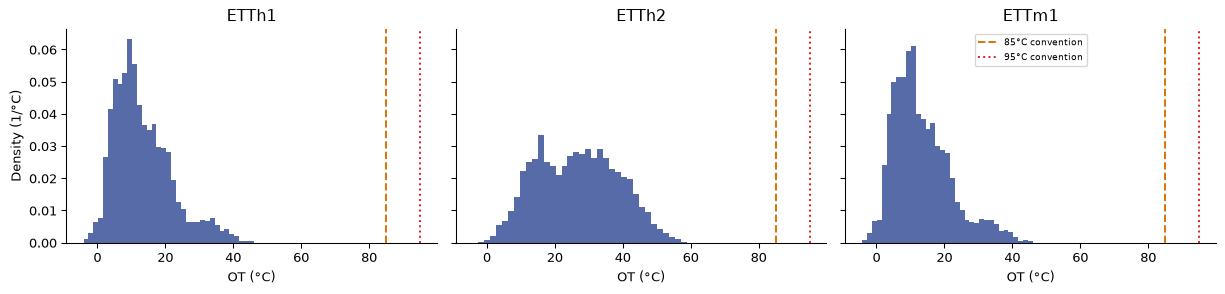

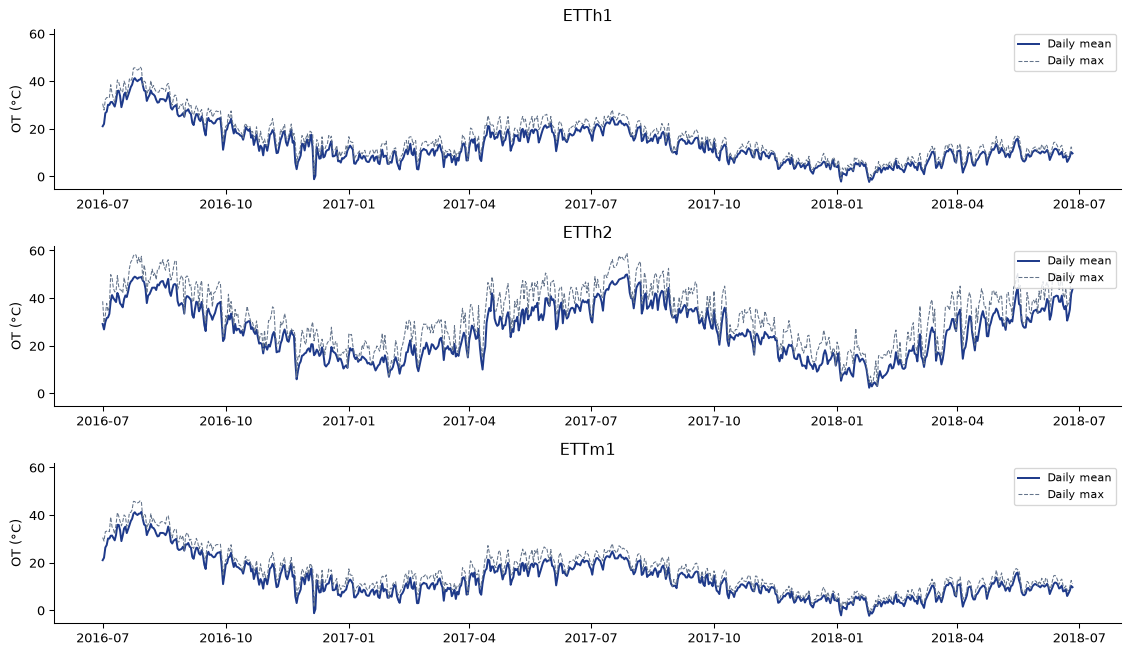

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True, sharey=True)
for ax, dataset in zip(axes, datasets):
    values = data.loc[data.dataset.eq(dataset), "OT"].dropna()
    ax.hist(values, bins=35, density=True, color=NAVY, alpha=0.75)
    ax.axvline(WARNING_TEMP_THRESHOLD, color=AMBER, ls="--", label="85°C convention")
    ax.axvline(CRITICAL_TEMP_THRESHOLD, color=CRIMSON, ls=":", label="95°C convention")
    ax.set(title=dataset, xlabel="OT (°C)")
axes[0].set_ylabel("Density (1/°C)")
axes[-1].legend(fontsize=7)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharey=True)
for ax, dataset in zip(axes, datasets):
    daily = data.loc[data.dataset.eq(dataset)].set_index("timestamp").OT.resample("D").agg(["mean", "max"])
    ax.plot(daily.index, daily["mean"], color=NAVY, label="Daily mean")
    ax.plot(daily.index, daily["max"], color=SLATE, ls="--", lw=0.8, label="Daily max")
    ax.set(title=dataset, ylabel="OT (°C)")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

### So sánh mô tả theo nhóm tháng và khung giờ khai báo
Khung 17:00–20:59 được khai báo **để thăm dò**, không phải giờ cao điểm đã
xác minh của lưới điện. Bảng chênh lệch không phải bằng chứng tải gây nhiệt;
tự tương quan, mùa, thời lượng bao phủ và yếu tố chưa quan sát có thể gây nhiễu.

In [4]:
data["hour_window"] = np.where(data.hour.between(17, 20), "17–20 exploratory", "Other hours")
season_summary = data.groupby(["dataset", "season"]).OT.agg(["count", "mean", "median", "std", "min", "max"])
window_summary = data.groupby(["dataset", "hour_window"]).OT.agg(["count", "mean", "median", "max"])
display(season_summary.round(3))
display(window_summary.round(3))
contrast = season_summary["mean"].unstack()
contrast["Wet_minus_Dry_C"] = contrast["Wet"] - contrast["Dry"]
display(contrast.round(3))

count       mean     median    std     min        max
dataset season                                                       
ETTh1   Dry      8688   8.109000   7.457000  4.814  -4.080  25.535999
        Wet      8732  18.514000  17.305000  8.329   2.673  46.007000
ETTh2   Dry      8688  17.905001  16.568001  8.215  -2.646  48.939999
        Wet      8732  35.270000  34.707001  8.026  14.272  58.876999
ETTm1   Dry     34752   8.108000   7.457000  4.815  -4.221  27.153999
        Wet     34928  18.507000  17.305000  8.327   2.251  46.007000

count       mean     median        max
dataset hour_window                                              
ETTh1   17–20 exploratory   2903  14.010000  12.029000  45.654999
        Other hours        14517  13.188000  11.185000  46.007000
ETTh2   17–20 exploratory   2903  28.733999  28.431999  54.702000
        Other hours        14517  26.184000  26.236000  58.876999
ETTm1   17–20 exploratory  11612  13.878000  11.889000  45.654999
        Other hours        58068  13.209000  11.256000  46.007000

season,Dry,Wet,Wet_minus_Dry_C
dataset,,,
ETTh1,8.109000,18.514,10.404
ETTh2,17.905001,35.270,17.365
ETTm1,8.108000,18.507,10.399


## 3. Chu kỳ giờ, thứ và tháng
Các dải q10–q90 là **80% empirical historical bands**, không phải confidence
interval của mean. Tổng hợp thứ/tháng không nhận định mùa địa phương.

hour | bins per dataset: {'ETTh1': 24, 'ETTh2': 24, 'ETTm1': 24}


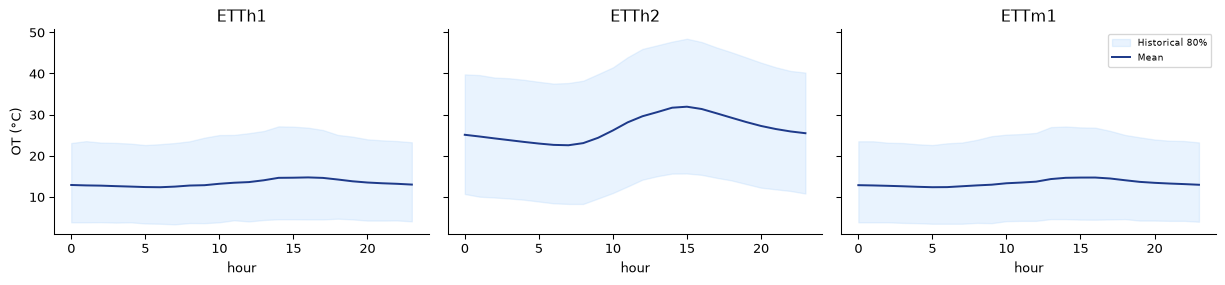

weekday | bins per dataset: {'ETTh1': 7, 'ETTh2': 7, 'ETTm1': 7}


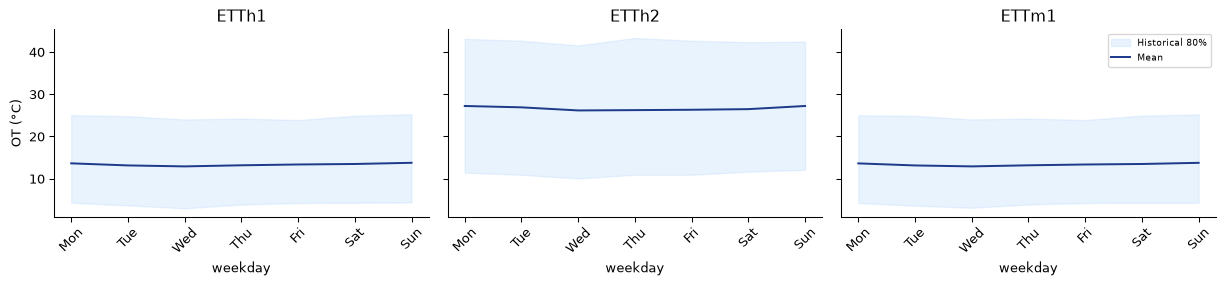

month | bins per dataset: {'ETTh1': 12, 'ETTh2': 12, 'ETTm1': 12}


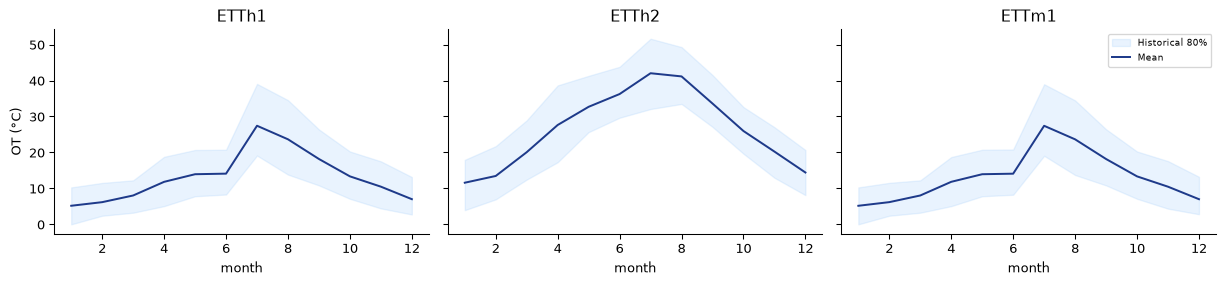

sample_count    mean  median    min        max    q10        q90
dataset hour                                                                  
ETTh1   0              726  12.873  10.798 -3.025  40.872002  3.799  23.073999
        1              726  12.771  10.693 -3.166  41.012001  3.799  23.531000
        2              726  12.715  10.693 -3.377  40.730999  3.834  23.180000
        3              726  12.592  10.587 -3.517  41.716000  3.728  23.108999
        4              726  12.486  10.482 -3.939  40.308998  3.799  22.933001
...                    ...     ...     ...    ...        ...    ...        ...
ETTm1   19            2904  13.630  11.678 -3.095  41.997002  4.221  24.459999
        20            2900  13.400  11.467 -2.955  41.293999  4.221  23.931999
        21            2900  13.227  11.256 -2.532  41.575001  4.150  23.636999
        22            2900  13.089  11.185 -2.744  41.223000  4.150  23.566000
        23            2900  12.928  10.904 -2.955  40.730999  3.939  23.215000

[72 rows x 7 columns]

In [5]:
cyclical = {}
for dimension in ["hour", "weekday", "month"]:
    table = data.groupby(["dataset", dimension]).OT.agg(
        sample_count="count", mean="mean", median="median", min="min", max="max",
        q10=lambda s: s.quantile(0.10), q90=lambda s: s.quantile(0.90))
    cyclical[dimension] = table
    print(dimension, "| bins per dataset:", table.groupby(level=0).size().to_dict())
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.1), sharey=True)
    for ax, dataset in zip(axes, datasets):
        sub = table.loc[dataset]
        ax.fill_between(sub.index, sub.q10, sub.q90, color="#93C5FD", alpha=0.20, label="Historical 80%")
        ax.plot(sub.index, sub["mean"], color=NAVY, label="Mean")
        ax.set(title=dataset, xlabel=dimension)
        if dimension == "weekday":
            ax.set_xticks(range(7), DAY_NAMES, rotation=45)
    axes[0].set_ylabel("OT (°C)"); axes[-1].legend(fontsize=7)
    plt.tight_layout(); plt.show()
display(cyclical["hour"].round(3))

## 4. Đỉnh quan sát và đối chiếu ngưỡng
Top-5 mẫu mỗi dataset là **mốc đáng chú ý**, không mặc định là sự cố.
Cột khoảng cách đến 85°C cho biết mức gần ngưỡng mà không tự đặt ngưỡng “cận nguy hiểm”.
Sample counts vượt ngưỡng không được nhân cadence để tạo event duration giả;
duration/Degree-Hours chỉ lấy từ artifact sự kiện có hỗ trợ đã kiểm toán.

In [6]:
top_ot = pd.concat([g.nlargest(5, "OT") for _, g in data.groupby("dataset")])
top_ot = top_ot[["dataset", "timestamp", "OT", "thermal_regime"]].copy()
top_ot["below_85_by_C"] = WARNING_TEMP_THRESHOLD - top_ot.OT
display(top_ot.reset_index(drop=True))
threshold_rows = []
for dataset, group in data.groupby("dataset"):
    valid = group.OT.dropna()
    for threshold in [WARNING_TEMP_THRESHOLD, CRITICAL_TEMP_THRESHOLD]:
        selected = events.loc[events.dataset.eq(dataset) & events.threshold_c.eq(threshold)]
        threshold_rows.append({"dataset": dataset, "threshold_C": threshold,
                               "valid_samples": len(valid), "samples_ge": int(valid.ge(threshold).sum()),
                               "sample_pct_ge": 100 * valid.ge(threshold).mean(),
                               "events": len(selected), "duration_h": selected.duration_hours.sum(),
                               "degree_hours_C_h": selected.degree_hours.sum()})
threshold_summary = pd.DataFrame(threshold_rows)
display(threshold_summary)
for dataset, group in data.groupby("dataset"):
    peak = group.loc[group.OT.idxmax()]
    display(Markdown(f"**Quan sát {dataset}:** OT cao nhất {peak.OT:.2f}°C tại {peak.timestamp}; "
                     f"cách ngưỡng 85°C {85 - peak.OT:.2f}°C. Đây không phải kết luận nguyên nhân."))

,dataset,timestamp,OT,thermal_regime,below_85_by_C
0,ETTh1,2016-07-29 15:00:00,46.007000,Normal,38.993000
1,ETTh1,2016-07-25 17:00:00,45.654999,Normal,39.345001
2,ETTh1,2016-07-24 17:00:00,45.444000,Normal,39.556000
3,ETTh1,2016-07-30 11:00:00,45.233002,Normal,39.766998
4,ETTh1,2016-07-24 18:00:00,45.091999,Normal,39.908001
5,ETTh2,2017-07-28 15:00:00,58.876999,Normal,26.123001
6,ETTh2,2016-07-25 15:00:00,58.437500,Normal,26.562500
7,ETTh2,2016-07-26 15:00:00,57.998001,Normal,27.001999
8,ETTh2,2017-07-28 14:00:00,57.998001,Normal,27.001999
9,ETTh2,2016-07-24 15:00:00,57.778500,Normal,27.221500


,dataset,threshold_C,valid_samples,samples_ge,sample_pct_ge,events,duration_h,degree_hours_C_h
0,ETTh1,85.0,17420,0,0.0,0,0.0,0.0
1,ETTh1,95.0,17420,0,0.0,0,0.0,0.0
2,ETTh2,85.0,17420,0,0.0,0,0.0,0.0
3,ETTh2,95.0,17420,0,0.0,0,0.0,0.0
4,ETTm1,85.0,69680,0,0.0,0,0.0,0.0
5,ETTm1,95.0,69680,0,0.0,0,0.0,0.0


**Quan sát ETTh1:** OT cao nhất 46.01°C tại 2016-07-29 15:00:00; cách ngưỡng 85°C 38.99°C. Đây không phải kết luận nguyên nhân.

**Quan sát ETTh2:** OT cao nhất 58.88°C tại 2017-07-28 15:00:00; cách ngưỡng 85°C 26.12°C. Đây không phải kết luận nguyên nhân.

**Quan sát ETTm1:** OT cao nhất 46.01°C tại 2016-07-29 15:00:00; cách ngưỡng 85°C 38.99°C. Đây không phải kết luận nguyên nhân.

## 5. Đối chiếu diagnostics tiền tính, không chạy lại engine
STL reconstruction trên hàng fit được; quantile nesting; lag/LOESS giữ scope
lịch sử. Những kiểm tra này bổ sung chứ không thay full audit T0205.

In [7]:
valid_stl = profiles.loc[profiles.record_type.eq("stl")].dropna(subset=["trend", "seasonal", "residual", "observed"])
np.testing.assert_allclose(valid_stl.observed, valid_stl.trend + valid_stl.seasonal + valid_stl.residual,
                           atol=1e-4, rtol=1e-5)
qcols = ["q025", "q10", "q25", "q50", "q75", "q90", "q975"]
assert not (bands[qcols].diff(axis=1).iloc[:, 1:] < 0).any().any()
assert all(np.shape(r["correlation_matrix"]) == (6, 13) for r in lag["records"])
assert np.isfinite(curves[["x_load", "y_ot_smooth"]]).all().all()
display(pd.DataFrame({"STL_fitted_rows": valid_stl.groupby("dataset").size(),
                      "quantile_rows": bands.groupby("dataset").size(),
                      "LOESS_rows": curves.groupby("dataset").size()}))
print("PASS: STL reconstruction, quantile nesting, saved lag shape, finite LOESS")

,STL_fitted_rows,quantile_rows,LOESS_rows
dataset,,,
ETTh1,156780,432,3600
ETTh2,156780,432,3600
ETTm1,627120,432,3600


PASS: STL reconstruction, quantile nesting, saved lag shape, finite LOESS


## 6. Kết luận và giả thuyết cần kiểm chứng
- **Quan sát:** Bảng, đồ thị và đỉnh nêu trên xuất phát trực tiếp từ artifacts đã hash-check.
- **Giả thuyết:** Thay đổi tải, điều kiện môi trường hoặc lịch vận hành có thể liên quan
  OT; dữ liệu hiện tại không đủ cô lập tác động hay kết luận nhánh tải gây sự cố.
- Gap count 0 nghĩa không phát hiện thiếu timestamp theo cadence trong cửa sổ nguồn;
  không chứng minh cảm biến hiệu chuẩn đúng hoặc dữ liệu đầy đủ ngoài cửa sổ đó.
- OT thiếu sẽ không được gán Normal; không trộn duration/Degree-Hours hai ngưỡng.
- Tự tương quan và unequal coverage làm phép kiểm định độc lập đơn giản không phù hợp;
  notebook không đưa p-value/causal claim khi chưa có thiết kế thống kê được duyệt.
- Sản phẩm là historical analytics, không prediction hay certified real-time safety.